# Left-wing vote share per municipality

This notebook maps the share of left-wing votes per municipality in the Tweede Kamer election of 29 October 2025.

**Definition of left-wing** (the same as in notebooks 0.3 and 6):
- **Broad (main definition):** GroenLinks-PvdA, SP, Partij voor de Dieren, DENK, BIJ1, D66 and Volt
- **Narrow (robustness check):** the same without D66 and Volt

**Required files:**
- `data/processed/left_wing_votes_per_municipality.csv`: left-wing vote share per municipality (% of valid votes), made by notebook 0.3
- `data/raw/gemeenten_2024.gpkg`: municipal boundaries from CBS/PDOK, 2024 municipal division
- `data/processed/chargingpoints_households_income.csv`: made by notebook 1, only used to check that the names match

**Output:**
- `figures/map_left_wing_votes_per_municipality.png`

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Load the data

Notebook 0.3 has already calculated the left-wing vote share from the election results, with the same municipality names as the charging point file. We check that all names match the charging point data.

In [2]:
left = pd.read_csv("../data/processed/left_wing_votes_per_municipality.csv")

print("Number of municipalities:", len(left))
display(left.describe().round(1))

# Check: does every municipality match the charging point data? Both lines should print set()
charging = pd.read_csv("../data/processed/chargingpoints_households_income.csv")
print("Only in the election data:", set(left["municipality"]) - set(charging["municipality"]))
print("Only in the charging data:", set(charging["municipality"]) - set(left["municipality"]))

Number of municipalities: 342


,left_wing_vote_pct,left_wing_vote_narrow_pct
count,342.0,342.0
mean,31.0,14.9
std,11.0,6.5
min,1.9,1.2
25%,24.0,10.5
50%,30.0,13.7
75%,36.2,18.2
max,71.2,45.1


Only in the election data: set()
Only in the charging data: set()


## 2. Join the data to the map

The boundary file uses CBS names, for example *'s-Gravenhage* instead of *Den Haag*. We convert these to the spelling of the charging point file, so the map can be joined on the municipality name.

In [3]:
municipalities = gpd.read_file("../data/raw/gemeenten_2024.gpkg", layer="gemeente_gegeneraliseerd")

# Names in the boundary file (left) -> spelling of the charging point file (right)
map_name_mapping = {
    "'s-Gravenhage": "Den Haag",
    "Beek (L.)": "Beek",
    "Hengelo (O.)": "Hengelo",
    "Laren (NH.)": "Laren",
    "Middelburg (Z.)": "Middelburg",
    "Rijswijk (ZH.)": "Rijswijk",
    "Stein (L.)": "Stein",
}
municipalities["municipality"] = municipalities["statnaam"].replace(map_name_mapping)

map_gdf = municipalities.merge(left, on="municipality", how="left")

# Check: should print 0
print("Municipalities without data:", map_gdf["left_wing_vote_pct"].isna().sum())

Municipalities without data: 0


## 3. Create the maps

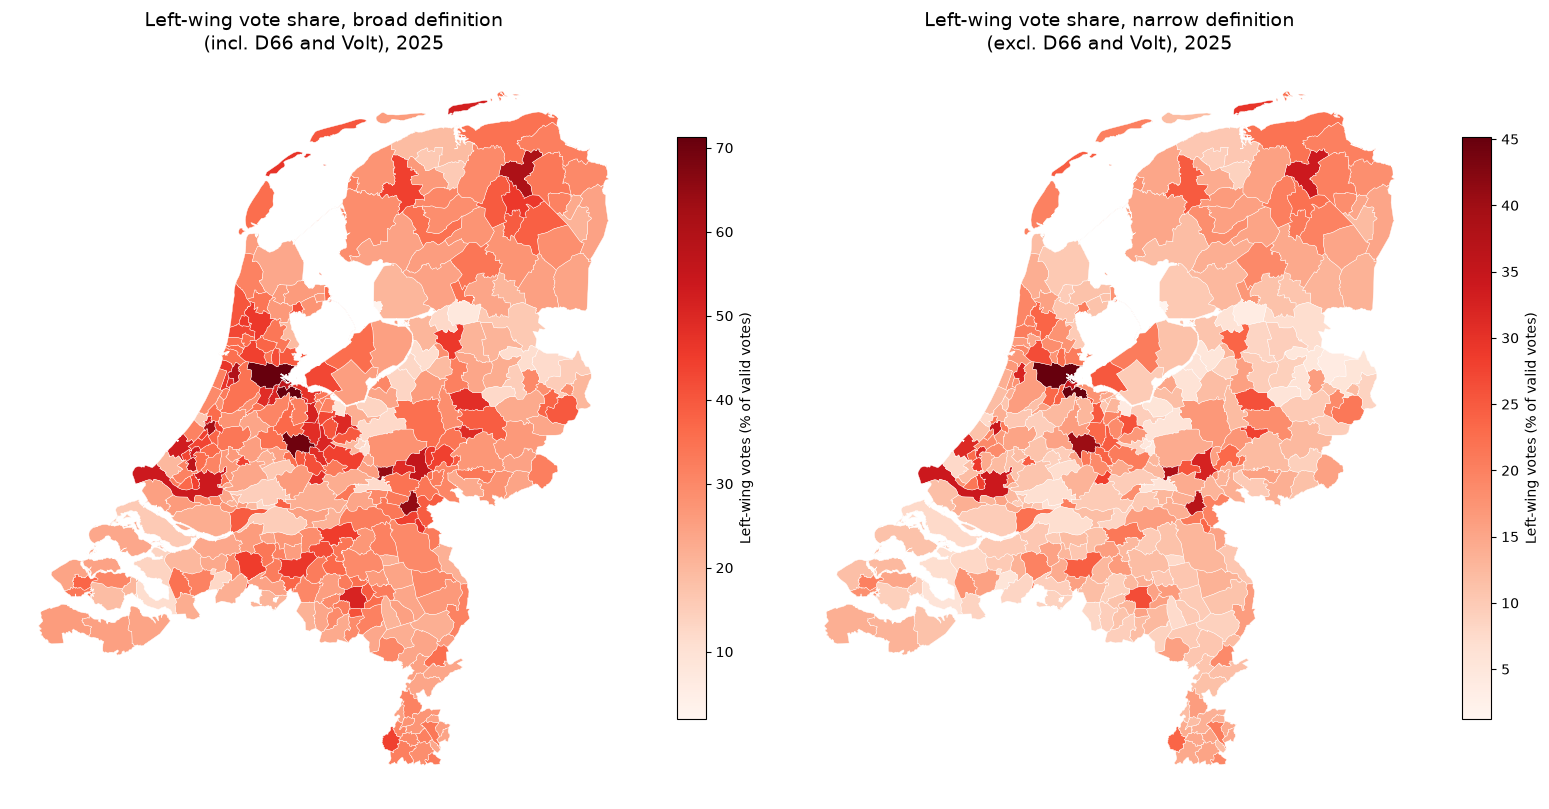

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

map_gdf.plot(
    column="left_wing_vote_pct",
    cmap="Reds",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "Left-wing votes (% of valid votes)", "shrink": 0.6},
    ax=axes[0],
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
axes[0].set_title("Left-wing vote share, broad definition\n(incl. D66 and Volt), 2025", fontsize=14)
axes[0].axis("off")

map_gdf.plot(
    column="left_wing_vote_narrow_pct",
    cmap="Reds",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "Left-wing votes (% of valid votes)", "shrink": 0.6},
    ax=axes[1],
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
axes[1].set_title("Left-wing vote share, narrow definition\n(excl. D66 and Volt), 2025", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/map_left_wing_votes_per_municipality.png", dpi=200)
plt.show()